# Lesson 3b: Muscle as an actuator, and the oxygen limit

**Goal:** model how engineered muscle produces force, and discover the biggest physical limit on
building large living actuators: getting oxygen to every cell.

### How skeletal muscle contracts (quick reminder)
An electrical pulse (or, with optogenetics, a light pulse) triggers calcium release inside the muscle
fibre, myosin pulls on actin, and the fibre produces a brief **twitch**. If pulses arrive faster than
a twitch can relax, the twitches **summate**; at high enough frequency they fuse into a smooth,
strong contraction called **tetanus**. Engineered muscle is usually stimulated exactly this way.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)

## 1. Twitches and summation

We model each pulse's twitch as a rise and decay (a difference of two exponentials), and the total
force as the sum of all twitches, capped at a maximum the muscle can produce. Parameters are
illustrative but in the range of fast muscle (twitch peaks in tens of milliseconds).

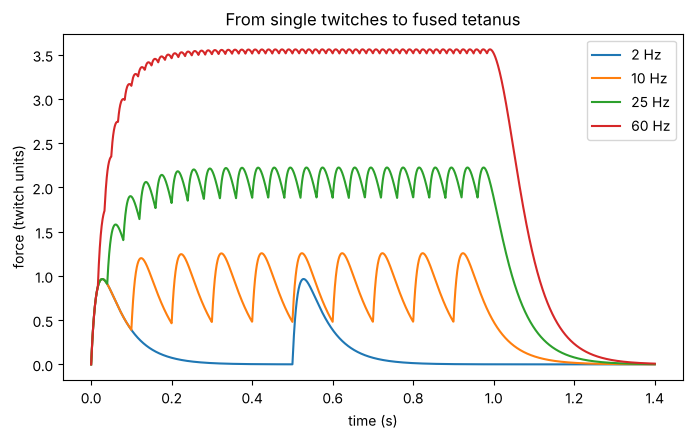

In [2]:
def twitch(t, tau_rise=0.015, tau_fall=0.06):
    """Normalised single-twitch force at time t (s) after a pulse."""
    t = np.clip(t, 0, None)
    f = np.exp(-t / tau_fall) - np.exp(-t / tau_rise)
    return f / 0.48   # roughly normalises the twitch peak to 1

def muscle_force(t, freq, duration=1.0, f_max=4.0):
    """Force (in twitch units) for a pulse train at `freq` Hz, saturating at f_max."""
    pulses = np.arange(0, duration, 1 / freq)
    total = sum(twitch(t - p) * (t >= p) for p in pulses)
    return f_max * np.tanh(total / f_max)   # smooth saturation

t = np.linspace(0, 1.4, 3000)
for f in [2, 10, 25, 60]:
    plt.plot(t, muscle_force(t, f), label=f"{f} Hz")
plt.xlabel("time (s)"); plt.ylabel("force (twitch units)"); plt.legend()
plt.title("From single twitches to fused tetanus")
plt.show()

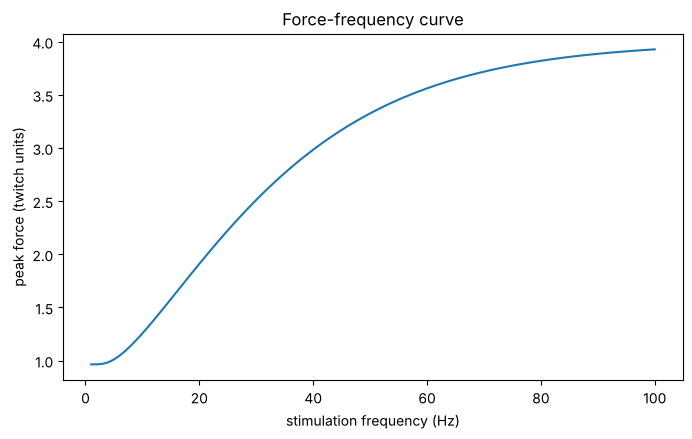

In [3]:
freqs = np.arange(1, 101)
peak = [muscle_force(t, f).max() for f in freqs]
plt.plot(freqs, peak)
plt.xlabel("stimulation frequency (Hz)"); plt.ylabel("peak force (twitch units)")
plt.title("Force-frequency curve")
plt.show()

A biohybrid robot designer uses this curve directly: low frequencies give separate kicks (good for
a walking gait), high frequencies give a sustained pull (good for gripping), at the cost of fatigue.

## 2. The oxygen limit

Here's the catch. Real muscle has capillaries every ~50 µm. Engineered tissue usually has none, so
oxygen has to **diffuse** in from the surrounding medium while cells consume it. For a slab of
tissue with oxygen supplied from both faces, at steady state:

$$D\,\frac{d^2C}{dx^2} = Q$$

where *D* is oxygen's diffusion coefficient in tissue and *Q* the cells' consumption rate. Solving it,
oxygen reaches zero at the centre when the half-thickness reaches

$$L_{max} = \sqrt{\frac{2 D C_0}{Q}}$$

Beyond that, the core starves and cells die (a **necrotic core**). Values below are typical orders of
magnitude for dense, active tissue.

Maximum half-thickness: 163 µm, so tissue thicker than ~327 µm starves


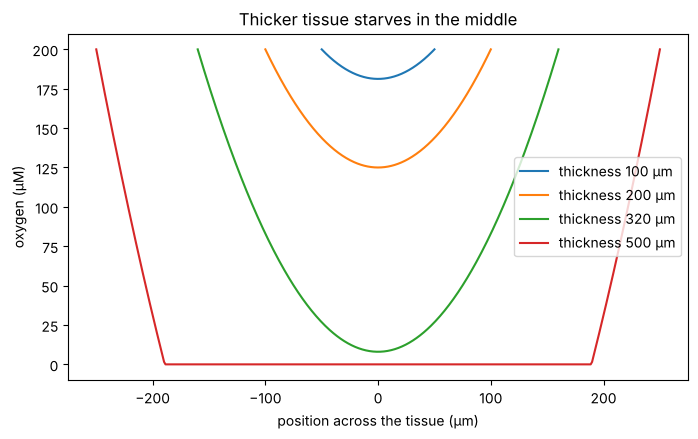

In [4]:
D = 2e-9      # m^2/s, oxygen diffusion in tissue
C0 = 0.2      # mol/m^3, oxygen in culture medium (about 0.2 mM)
Q = 0.03      # mol/(m^3 s), consumption by densely packed active cells

L_max = np.sqrt(2 * D * C0 / Q)
print(f"Maximum half-thickness: {L_max * 1e6:.0f} µm, so tissue thicker than ~{2 * L_max * 1e6:.0f} µm starves")

def oxygen_profile(x, L, D=D, C0=C0, Q=Q):
    """Steady-state O2 across a slab of half-thickness L (x from -L to L), floored at zero."""
    C = C0 - Q / (2 * D) * (L**2 - x**2)
    return np.clip(C, 0, None)

for L_um in [50, 100, 160, 250]:
    L = L_um * 1e-6
    x = np.linspace(-L, L, 400)
    plt.plot(x * 1e6, oxygen_profile(x, L) * 1e3, label=f"thickness {2 * L_um} µm")
plt.xlabel("position across the tissue (µm)"); plt.ylabel("oxygen (µM)"); plt.legend()
plt.title("Thicker tissue starves in the middle")
plt.show()

(The simple formula above stops being exact once oxygen hits zero, because dead cells stop
consuming, but it shows the scaling well.)

## 3. Design consequence: how strong can a living actuator be?

Muscle force scales with **cross-sectional area**. If each strand can be at most ~300 µm thick,
the only ways to get more force are more strands, or getting oxygen inside. Let's compare a single
thick block of tissue with a bundle of thin strands of the same total volume.

In [5]:
specific_stress = 2e3   # Pa of active stress for engineered muscle (illustrative; native muscle is far higher)

def living_force(diameter_um, n_strands=1):
    """Force from n cylindrical strands; only the outer, oxygenated shell contributes."""
    r = diameter_um / 2 * 1e-6
    alive_r_inner = max(r - L_max, 0)            # core beyond L_max from the surface is dead
    alive_area = np.pi * (r**2 - alive_r_inner**2)
    return n_strands * specific_stress * alive_area

for d, n in [(2000, 1), (600, 11), (300, 44)]:
    F = living_force(d, n)
    print(f"{n:>3} strand(s) of {d:>4} µm: force = {F * 1e6:6.1f} µN")

  1 strand(s) of 2000 µm: force = 1884.5 µN
 11 strand(s) of  600 µm: force = 4928.8 µN
 44 strand(s) of  300 µm: force = 6220.4 µN


Same amount of tissue, very different force: the thick block wastes most of its volume as a dead core.

That's why the frontier of the field is about **perfusion and vascularisation**: building channels,
hollow fibres or real blood-vessel networks into tissue so it can grow beyond the diffusion limit.
The same problem limits lab-grown organs, cultured meat and organoids.

## Recap

- Muscle actuators are controlled by stimulation frequency: twitches summate into tetanus.
- Without blood vessels, oxygen diffusion caps living tissue at a few hundred micrometres thick.
- Smart geometry (many thin strands) beats bulk, and vascularisation is the key open problem.

**Your turn:**
1. Engineered tissue often uses cells at lower density. Halve `Q`. How much thicker can the tissue get? (Look at the formula first and predict.)
2. Some groups culture tissue in medium with extra oxygen or oxygen carriers. Double `C0`. Is that as effective as halving `Q`?
3. Design challenge: with 2 mm³ of tissue in strands of equal length, which strand diameter maximises force? Write a small loop over diameters to find out.